# Lecture 10: Evaluating regression predictions

This demo is based on [Lecture 10 notes](https://ubc-cs.github.io/cpsc330-book/book/10_regression-metrics.html).
How far off are our house-price predictions, and which mistakes matter most? We will build a ridge pipeline, compare regression metrics, and investigate a log-transformed target.

Our workflow: reserve a test set $\to$ review preprocessing $\to$ tune ridge $\to$ choose an evaluation metric $\to$ compare target scales $\to$ evaluate once. By the end, you should be able to interpret errors in dollars and percentages and distinguish model fitting from model selection.

## Setup and imports

Run this notebook from `content/classes/varada` using this directory's `.venv` kernel. Place the labelled [Kaggle House Prices data](https://www.kaggle.com/c/home-data-for-ml-course/) at `data/housing-kaggle/train.csv`, with `data_description.txt` alongside it. Run the cells in order.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor, make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    make_scorer, mean_absolute_error, mean_absolute_percentage_error,
    mean_squared_error, r2_score,
)
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

%matplotlib inline
DATA_DIR = Path("data")
CV = 5


## 1. Load, split, and review preprocessing

We predict `SalePrice` in dollars. For this demo, assume the recorded property and sale information is available at prediction time. Reserve 10% of the labelled data for final evaluation; predicting future sales would require a time-aware split.

The CSV reader treats `NA` and empty entries as missing but preserves `None`, which means no masonry veneer in `MasVnrType`.

In [2]:
df = pd.read_csv(
    DATA_DIR / "housing-kaggle/train.csv",
    keep_default_na=False,
    na_values=["", "NA"],
)
train_df, test_df = train_test_split(df, test_size=0.10, random_state=123)
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
302,303,20,RL,118.0,13704,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2006,WD,Normal,205000
767,768,50,RL,75.0,12508,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,1300,7,2008,WD,Normal,160000
429,430,20,RL,130.0,11457,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Normal,175000
1139,1140,30,RL,98.0,8731,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,144000
558,559,60,RL,57.0,21872,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,8,2008,WD,Normal,175000


In [3]:
X_train = train_df.drop(columns=["SalePrice"])
y_train = train_df["SalePrice"]

X_test = test_df.drop(columns=["SalePrice"])
y_test = test_df["SalePrice"]

X_train.shape

(1314, 80)

### Inspect the training data

Which columns need investigation? Stored types, missing fractions, and distinct-value counts are clues; use the data description to interpret them.

In [4]:
feature_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_fraction": X_train.isna().mean(),
    "distinct_values": X_train.nunique(),
})
feature_summary.sort_values("missing_fraction", ascending=False).head(15)

,dtype,missing_fraction,distinct_values
PoolQC,object,0.994673,3
MiscFeature,object,0.961948,4
Alley,object,0.938356,2
Fence,object,0.802892,4
FireplaceQu,object,0.477169,5
LotFrontage,float64,0.171233,104
GarageType,object,0.055556,6
GarageYrBlt,float64,0.055556,97
GarageQual,object,0.055556,5
GarageCond,object,0.055556,5


**Discuss:** `PoolQC` is mostly missing. Should we drop it?

The data description says `NA` means no pool. For numerical features, check ranges too: does zero mean absence, or is a measurement unknown?

In [5]:
X_train[["LotArea", "LotFrontage", "YearBuilt", "GarageYrBlt"]].describe()

,LotArea,LotFrontage,YearBuilt,GarageYrBlt
count,1314.000000,1089.000000,1314.000000,1241.000000
mean,10273.261035,69.641873,1970.995434,1978.209508
std,8997.895541,23.031794,30.198127,24.759774
min,1300.000000,21.000000,1872.000000,1900.000000
25%,7500.000000,59.000000,1953.000000,1961.000000
50%,9391.000000,69.000000,1972.000000,1979.000000
75%,11509.000000,80.000000,2000.000000,2002.000000
max,215245.000000,313.000000,2010.000000,2010.000000


### Absence is different from unknown information

**Predict:** How should we represent missing `FireplaceQu` when `Fireplaces` is 0? What if it is 1?

The helper below marks missing descriptions as `Absent` when a related count or area is zero. Other missing descriptions remain unknown. These fixed, row-wise rules can be applied to both splits; learned imputation stays inside the pipeline.

In [6]:
def mark_absent_amenities(X):
    X = X.copy()
    amenity_columns = {
        "TotalBsmtSF": ["BsmtQual", "BsmtCond", "BsmtExposure",
                        "BsmtFinType1", "BsmtFinType2"],
        "Fireplaces": ["FireplaceQu"],
        "GarageArea": ["GarageType", "GarageFinish", "GarageQual", "GarageCond"],
        "PoolArea": ["PoolQC"],
    }
    for measurement, columns in amenity_columns.items():
        absent = X[measurement].eq(0)
        X.loc[absent, columns] = X.loc[absent, columns].fillna("Absent")

    for column in ["Alley", "Fence", "MiscFeature"]:
        X[column] = X[column].fillna("Absent")
    return X


X_train = mark_absent_amenities(X_train)
X_test = mark_absent_amenities(X_test)
X_train[["Fireplaces", "FireplaceQu", "GarageArea", "GarageQual"]].head(10)

,Fireplaces,FireplaceQu,GarageArea,GarageQual
302,1,TA,843,TA
767,0,Absent,423,TA
429,1,TA,576,TA
1139,1,Gd,495,TA
558,1,TA,406,TA
761,0,Absent,440,TA
1046,1,Gd,716,TA
1265,0,Absent,506,TA
1187,1,Fa,757,TA
783,1,TA,602,TA


Check the prepared rows above. A house with a fireplace and missing quality should still have an unknown rating.

For numerical values, we will use median imputation plus missing-value indicators, preserving information such as an unrecorded `GarageYrBlt`.

### Choose representations from meanings

**Discuss:** Should `MSSubClass = 60` represent three times as much dwelling as `20`?

| Feature | Demo representation | Why? |
|---|---|---|
| `Id` | Drop | Record identifier |
| `LotArea` | Impute and scale | Quantitative measurement |
| `MSSubClass`, `MoSold` | One-hot encode | Codes or seasonal categories |
| `ExterQual` | Ordinal encode and scale | Ordered quality ratings |
| `FireplaceQu` | One-hot encode | Keep absence separate from quality |

In [7]:
numeric_looking_columns = X_train.select_dtypes(include=np.number).columns.tolist()
X_train[["MSSubClass", "MoSold"]].head()

,MSSubClass,MoSold
302,20,1
767,50,7
429,20,3
1139,30,5
558,60,8


### Collect the feature groups

Numeric features include measurements, counts, years, and the 1–10 overall ratings. Treating years and ratings as numeric is a starting assumption: ridge assigns a constant contribution per unit increase.

We encode dwelling codes and sale months as categories. One-hot encoding months allows separate seasonal effects, but does not encode December's closeness to January.

In [8]:
drop_features = ["Id"]
numeric_features = [
    "BedroomAbvGr",
    "KitchenAbvGr",
    "LotFrontage",
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageYrBlt",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "YrSold",
]

In [9]:
# Numeric-looking columns that we will encode as categories.
[column for column in numeric_looking_columns
 if column not in numeric_features + drop_features]

['MSSubClass', 'MoSold']

Quality ratings have an explicit order: `Po < Fa < TA < Gd < Ex`. `Functional` uses a separate scale.

**Discuss:** What assumption does encoding these levels as consecutive integers introduce for a linear model?

It assumes equal steps in predicted price. Scaling does not remove that assumption.

In [10]:
ordinal_features_reg = ["ExterQual", "ExterCond", "HeatingQC", "KitchenQual"]
ordering = ["Po", "Fa", "TA", "Gd", "Ex"]
ordering_ordinal_reg = [ordering] * len(ordinal_features_reg)

ordinal_features_oth = ["Functional"]
ordering_ordinal_oth = [
    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
]

One-hot encode the remaining categories, including amenity descriptions with `Absent`. This avoids placing absence on a quality scale.

Inspect the list against the data description; being left over is not enough to justify an encoding.

In [11]:
assigned_features = (
    drop_features + numeric_features + ordinal_features_reg + ordinal_features_oth
)
categorical_features = [
    column for column in X_train.columns if column not in assigned_features
]
categorical_features

['MSSubClass',
 'MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'CentralAir',
 'Electrical',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'MoSold',
 'SaleType',
 'SaleCondition']

Check that each input column belongs to exactly one group.

In [12]:
all_features = assigned_features + categorical_features
assert len(all_features) == len(set(all_features)), "A feature appears in multiple groups."
assert set(all_features) == set(X_train.columns), "Check for missing or extra features."

**Discuss:** Could we add `SalePrice / GrLivArea` as an input to predict `SalePrice` for a new house? Which information would be available then?

### Build the preprocessor

| Group | Missing values | Transformation |
|---|---|---|
| Numeric | Median + missing indicators | Standard scaling |
| Ordinal | Most frequent category | Ordered encoding + scaling |
| Categorical | Explicit `Unknown` category | One-hot encoding |
| Identifier | — | Drop |

Scale numerical and ordinal inputs because ridge's penalty depends on coefficient units. Keep one-hot indicators as 0/1. `handle_unknown="ignore"` maps unseen categories to all-zero indicators; that differs from the explicit missing-value category `Unknown`. Dense output makes the table easy to inspect.

In [13]:
numeric_transformer = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
)
ordinal_transformer_reg = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_reg),
    StandardScaler(),
)
ordinal_transformer_oth = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_oth),
    StandardScaler(),
)
categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="Unknown"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    ("drop", drop_features),
    (numeric_transformer, numeric_features),
    (ordinal_transformer_reg, ordinal_features_reg),
    (ordinal_transformer_oth, ordinal_features_oth),
    (categorical_transformer, categorical_features),
    verbose_feature_names_out=False,
)

### Inspect the transformed features

Fit on training inputs for inspection and recover the feature names. Can you find the indicator for an absent fireplace?

In [14]:
preprocessor.fit(X_train)
new_columns = preprocessor.get_feature_names_out()
X_train_enc = pd.DataFrame(
    preprocessor.transform(X_train), index=X_train.index, columns=new_columns
)
X_train_enc.head()

,BedroomAbvGr,KitchenAbvGr,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
302,0.154795,-0.222647,2.312501,0.381428,0.663680,-0.512408,0.993969,0.840492,0.269972,-0.961498,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
767,1.372763,-0.222647,0.260890,0.248457,-0.054669,1.285467,-1.026793,0.016525,-0.573129,0.476092,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
429,0.154795,-0.222647,2.885044,0.131607,-0.054669,-0.512408,0.563314,0.161931,-0.573129,1.227559,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1139,0.154795,-0.222647,1.358264,-0.171468,-0.773017,-0.512408,-1.689338,-1.679877,-0.573129,0.443419,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
558,0.154795,-0.222647,-0.597924,1.289541,0.663680,-0.512408,0.828332,0.598149,-0.573129,0.354114,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [15]:
print(f"Original features: {X_train.shape[1]}")
print(f"Transformed features: {X_train_enc.shape[1]}")
assert X_train_enc.columns.is_unique
assert np.isfinite(X_train_enc.to_numpy()).all()

# Check that houses without fireplaces retain that information.
X_train_enc.loc[
    X_train["Fireplaces"].eq(0),
    X_train_enc.columns.str.startswith("FireplaceQu_"),
].head()

Original features: 80
Transformed features: 313


,FireplaceQu_Absent,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_Po,FireplaceQu_TA
767,1.0,0.0,0.0,0.0,0.0,0.0
761,1.0,0.0,0.0,0.0,0.0,0.0
1265,1.0,0.0,0.0,0.0,0.0,0.0
679,1.0,0.0,0.0,0.0,0.0,0.0
1269,1.0,0.0,0.0,0.0,0.0,0.0


**Find the leak:** Why would cross-validating ridge on `X_train_enc` be incorrect?

For evaluation, pass the prepared input table and the **complete pipeline**. Each fold must learn imputation, scaling, and category vocabularies from its fitting rows.

## 2. Establish a baseline and tune ridge

`DummyRegressor` predicts the fitting rows' mean price. Does ridge improve on that baseline?

Start with $R^2$, the default regression score: 1 is perfect, 0 matches the evaluation-target mean, and negative is worse. The dummy can score below zero because its training mean differs from the validation mean. Use the same five folds for both models.

In [16]:
pipe_ridge = make_pipeline(preprocessor, Ridge())
cv_results = {}
for name, model in {"Dummy": DummyRegressor(), "Ridge": pipe_ridge}.items():
    cv_results[name] = cross_validate(
        model, X_train, y_train, cv=CV, scoring="r2", return_train_score=True
    )

pd.DataFrame({
    name: {
        "mean training R2": result["train_score"].mean(),
        "mean validation R2": result["test_score"].mean(),
        "validation R2 std": result["test_score"].std(),
    }
    for name, result in cv_results.items()
}).T

,mean training R2,mean validation R2,validation R2 std
Dummy,0.000000,-0.005307,0.005636
Ridge,0.925095,0.787773,0.097746


### Tune regularization

**Predict:** As `alpha` increases, what should happen to training performance?

Larger `alpha` means stronger regularization—the opposite direction to logistic regression's `C`. Search the complete pipeline using `ridge__alpha`, then inspect training and validation curves.

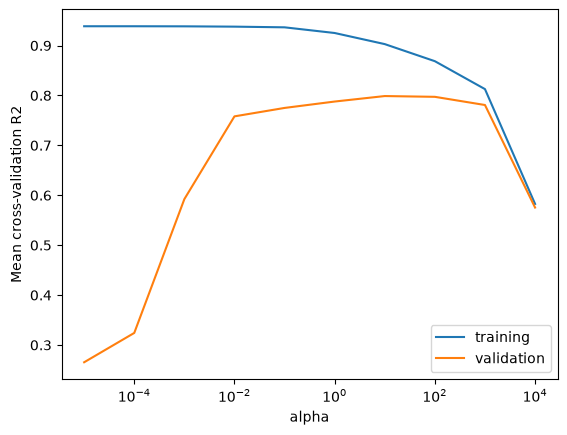

In [17]:
param_grid = {"ridge__alpha": 10.0 ** np.arange(-5, 5)}
search = GridSearchCV(
    pipe_ridge, param_grid, cv=CV, scoring="r2",
    return_train_score=True, n_jobs=1,
)
search.fit(X_train, y_train)

plt.semilogx(
    param_grid["ridge__alpha"], search.cv_results_["mean_train_score"], label="training"
)
plt.semilogx(
    param_grid["ridge__alpha"], search.cv_results_["mean_test_score"], label="validation"
)
plt.xlabel("alpha")
plt.ylabel("Mean cross-validation R2")
plt.legend();

**Discuss:** Which region of the curve would you choose? Why not select the highest training score?

The search chooses the highest mean validation $R^2$ and refits the winning pipeline on all training rows.

In [18]:
best_alpha = search.best_params_["ridge__alpha"]
ridge_tuned = search.best_estimator_
print(f"Selected alpha: {best_alpha:g}")
print(f"Best mean validation R2: {search.best_score_:.3f}")

Selected alpha: 10
Best mean validation R2: 0.799


### Inspect a few coefficients

Compare weak, selected, and strong regularization on the same training data. `clone` gives each comparison an independent pipeline.

In [19]:
features_to_compare = [
    "OverallQual", "GrLivArea", "KitchenQual", "Neighborhood_Edwards"
]
selected_preprocessor = ridge_tuned.named_steps["columntransformer"]
selected_coefficients = pd.Series(
    ridge_tuned.named_steps["ridge"].coef_,
    index=selected_preprocessor.get_feature_names_out(),
)
coefficient_comparison = {}
for label, alpha in [("Weak (0.01)", 0.01), ("Strong (1000)", 1000)]:
    model = clone(pipe_ridge).set_params(ridge__alpha=alpha)
    model.fit(X_train, y_train)
    coefficient_comparison[label] = pd.Series(
        model.named_steps["ridge"].coef_,
        index=model.named_steps["columntransformer"].get_feature_names_out(),
    )

selected_label = f"Selected ({best_alpha:g})"
coefficient_comparison[selected_label] = selected_coefficients
pd.DataFrame(coefficient_comparison).loc[
    features_to_compare, ["Weak (0.01)", selected_label, "Strong (1000)"]
].round(0)

,Weak (0.01),Selected (10),Strong (1000)
OverallQual,10291.0,13450.0,9137.0
GrLivArea,15589.0,14462.0,7549.0
KitchenQual,3744.0,4167.0,5567.0
Neighborhood_Edwards,-16983.0,-15072.0,-1118.0


Stronger regularization shrinks the coefficient vector overall; individual coefficients need not shrink monotonically when features are correlated.

**Discuss:** What are the units of the `OverallQual` coefficient after scaling? How does interpreting it differ from a one-hot neighbourhood coefficient?

These are associations, not causal effects. Use validation performance to choose `alpha`; keep the test set reserved.

## 3. What do the errors mean?

Use training predictions to understand the calculations below. These scores do **not** estimate performance on new houses.

### MAE: average absolute error in dollars

$$\operatorname{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|.$$

Each additional dollar of absolute error contributes equally. Absolute values prevent positive and negative errors from cancelling.

In [20]:
preds = ridge_tuned.predict(X_train)
mae = mean_absolute_error(y_train, preds)
print(f"Training MAE: ${mae:,.0f}")

# The same calculation using NumPy.
np.mean(np.abs(y_train - preds))

Training MAE: $15,592


np.float64(15592.325430847972)

MAE describes an average, not a bound on each prediction's error.

### MSE: give large mistakes more influence

$$\operatorname{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2.$$

**Predict:** How much does a $20,000 error contribute compared with a $10,000 error, under MAE and MSE?

In [21]:
mse = mean_squared_error(y_train, preds)
pd.Series({
    "MSE (NumPy)": np.mean((y_train - preds) ** 2),
    "MSE (scikit-learn)": mse,
})

MSE (NumPy)           6.447903e+08
MSE (scikit-learn)    6.447903e+08
dtype: float64

MSE is measured in **squared dollars**. Take its square root to return to dollars.

### RMSE: squared-error emphasis in dollar units

$$\operatorname{RMSE} = \sqrt{\operatorname{MSE}}.$$

Like MAE, smaller is better. RMSE gives large mistakes more influence.

In [22]:
rmse = np.sqrt(mse)
print(f"Training MAE:  ${mae:,.0f}")
print(f"Training RMSE: ${rmse:,.0f}")

Training MAE:  $15,592
Training RMSE: $25,393


### Same MAE, different mistakes

Model A misses by $\$30,000$ once and is exactly right twice. Model B misses by $\$10,000$ on all three houses.

**Predict:** Which model will MAE prefer? Which will RMSE prefer?

In [23]:
example_errors = pd.DataFrame({
    "Model A": [0, 0, 30_000],
    "Model B": [10_000, 10_000, 10_000],
})
pd.DataFrame({
    "MAE ($)": example_errors.abs().mean(),
    "RMSE ($)": np.sqrt((example_errors ** 2).mean()),
}).round(0)

,MAE ($),RMSE ($)
Model A,10000.0,17321.0
Model B,10000.0,10000.0


MAE ties; RMSE prefers Model B. Which judgment matches the consequences of errors in your application?

MSE and RMSE rank models identically on one fixed evaluation set. RMSE is at least as large as MAE on the same predictions; neither bounds individual errors.

### Inspect the errors

A single score hides direction and patterns. Where does the model overpredict?

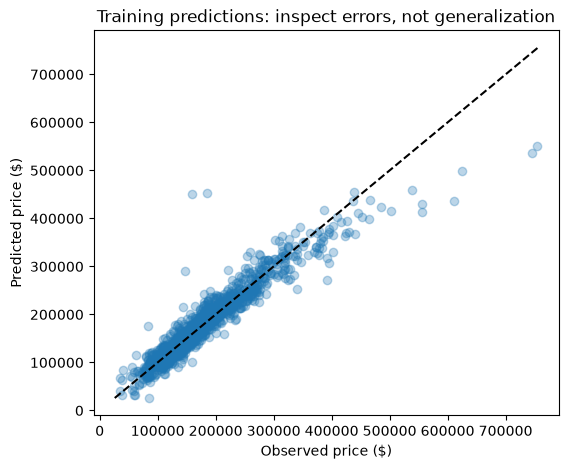

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_train, preds, alpha=0.3)
limits = [min(y_train.min(), preds.min()), max(y_train.max(), preds.max())]
ax.plot(limits, limits, "--k")
ax.set(xlabel="Observed price ($)", ylabel="Predicted price ($)",
       title="Training predictions: inspect errors, not generalization");


Above the dashed line means overprediction; below means underprediction. Count the directions as well as inspecting the plot.

In [25]:
# Positive errors indicate overprediction; negative errors indicate underprediction.
errors = preds - y_train
print(f"Overpredictions: {(errors > 0).mean():.1%}")
print(f"Underpredictions: {(errors < 0).mean():.1%}")
print(f"Exact matches: {(errors == 0).mean():.1%}")

Overpredictions: 50.5%
Underpredictions: 49.5%
Exact matches: 0.0%


Similar overprediction and underprediction counts can still hide very different error magnitudes.

### $R^2$: compare squared error with a reference

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}.$$

Here $\bar{y}$ is the **evaluation targets' mean**. A score of 1 is perfect, 0 matches that reference, and negative is worse. Keep the argument order `r2_score(y_true, y_pred)`.

In [26]:
r2_score(y_train, preds)

0.8967140073405423

**Discuss:** Does $R^2 = 0.8$ mean 80% of predictions are correct?

It means squared error is 20% of the reference's squared error. Pair $R^2$ with a dollar-based metric; its value depends on target variation.

### MAPE: proportional error

$$\operatorname{MAPE} = \frac{1}{n}\sum_i\frac{|y_i-\hat{y}_i|}{|y_i|}.$$

**Predict:** A $\$30,000$ error occurs on a $\$60,000$ house and a $\$600,000$ house. Which contributes more to MAPE?

Scikit-learn returns a proportion; display it as a percentage.

In [27]:
mape = mean_absolute_percentage_error(y_train, preds)
print(f"Training MAPE: {mape:.1%}")

Training MAPE: 9.3%


MAPE gives the same dollar error more weight for a cheaper house. Avoid it when true values can be zero or near zero; ratios also require a meaningful zero.

**Discuss:** Choose a primary metric for each goal:

- Each additional dollar of error should count equally.
- Large errors in delivery time should receive extra emphasis.
- Relative house-price errors matter more than dollar errors.

Would any of these metrics capture late deliveries being more costly than equally early ones?

## 4. Use metrics in cross-validation and selection

Scikit-learn scorers use **higher is better**, so error scorers return negative errors: −20,000 is better than −30,000. Convert them back to positive errors when reporting.

Evaluate the default ridge pipeline using several metrics on the same folds.

In [28]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error",
}
metric_cv = cross_validate(pipe_ridge, X_train, y_train, cv=CV, scoring=scoring)
fold_metrics = pd.DataFrame({
    name: metric_cv[f"test_{name}"] * (1 if name == "R2" else -1)
    for name in scoring
})
fold_metrics.agg(["mean", "std"])

,MAE,RMSE,R2,MAPE
mean,19948.107208,35443.433595,0.787773,0.120470
std,848.934313,7967.747092,0.109283,0.004343


Read each column in its own units: MAE/RMSE in dollars, MAPE as a proportion, and $R^2$ unitless. Fold standard deviations describe variation, not confidence intervals.

### Select using the metric that matters

For this experiment, choose proportional accuracy as the goal. `refit="MAPE"` selects by MAPE and refits the winning pipeline, while recording the other metrics.

**Predict:** Does setting the scorer to MAPE make ridge minimize MAPE during fitting?

Each candidate still fits squared error plus regularization. The scorer changes which fitted candidate we select.

In [29]:
# Reuse the candidates and folds from the earlier R2 search.
search_multi = GridSearchCV(
    pipe_ridge, param_grid, cv=CV, scoring=scoring,
    refit="MAPE", n_jobs=1,
)
search_multi.fit(X_train, y_train)

print(f"Alpha selected by R2: {best_alpha:g}")
print(f"Alpha selected by MAPE: {search_multi.best_params_['ridge__alpha']:g}")
print(f"Best mean validation MAPE: {-search_multi.best_score_:.1%}")

search_results = pd.DataFrame({
    "alpha": search_multi.cv_results_["param_ridge__alpha"],
    "validation MAE ($)": -search_multi.cv_results_["mean_test_MAE"],
    "validation RMSE ($)": -search_multi.cv_results_["mean_test_RMSE"],
    "validation R2": search_multi.cv_results_["mean_test_R2"],
    "validation MAPE": -search_multi.cv_results_["mean_test_MAPE"],
})
search_results.sort_values("validation MAPE")

Alpha selected by R2: 10
Alpha selected by MAPE: 100
Best mean validation MAPE: 10.8%


,alpha,validation MAE ($),validation RMSE ($),validation R2,validation MAPE
7,100.00000,18439.103997,34588.595166,0.797221,0.107837
6,10.00000,18967.599660,34505.533400,0.798765,0.113861
8,1000.00000,20223.795987,36552.819885,0.780828,0.114111
5,1.00000,19948.107208,35443.433595,0.787773,0.120470
4,0.10000,20093.332901,36461.481682,0.774963,0.122563
3,0.01000,20516.075872,37950.666972,0.758069,0.125322
2,0.00100,21839.878322,48138.435724,0.592270,0.131976
1,0.00010,22947.416027,58668.134654,0.324146,0.137788
0,0.00001,23139.281784,60552.993172,0.265411,0.138816
9,10000.00000,33238.628539,51365.984646,0.575381,0.201075


Compare the selected `alpha` values and the metric columns. Agreement between metrics is possible. Next, compare target scales using training-set CV before final evaluation.

## 5. Compare a log-transformed target

A log transformation compresses large prices more than small ones. Will this help proportional accuracy? A less skewed histogram alone cannot answer that question.

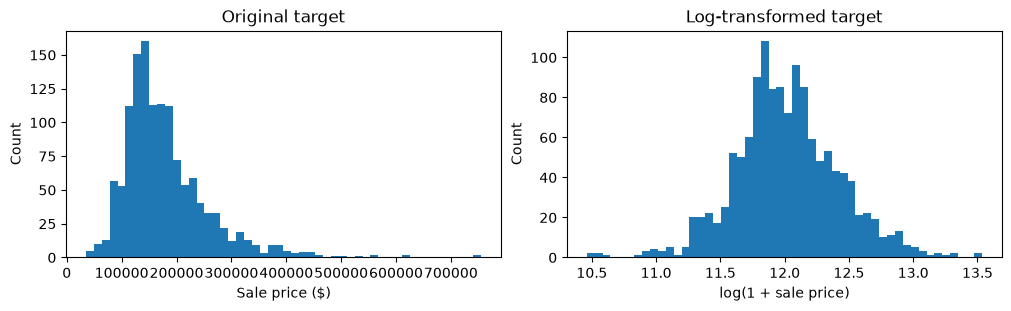

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].hist(y_train, bins=50)
axes[0].set(xlabel="Sale price ($)", ylabel="Count", title="Original target")
axes[1].hist(np.log1p(y_train), bins=50)
axes[1].set(xlabel="log(1 + sale price)", ylabel="Count", title="Log-transformed target");


### Fit and predict with `TransformedTargetRegressor`

The wrapper transforms training targets with `log1p` and reverses the transformation with `expm1` when predicting. Predictions and evaluation metrics remain in the original price scale.

**Discuss:** Why does target transformation belong outside the `ColumnTransformer`?

In [31]:
ttr = TransformedTargetRegressor(
    regressor=Ridge(), func=np.log1p, inverse_func=np.expm1
)
ttr_pipe = make_pipeline(preprocessor, ttr)
ttr_pipe


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('transformedtargetregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('drop', ...), ('pipeline-1', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and `

Tune `alpha` again on the transformed scale, using the same folds and MAPE criterion as the original-target search.

In [32]:
log_search = GridSearchCV(
    ttr_pipe,
    {"transformedtargetregressor__regressor__alpha": param_grid["ridge__alpha"]},
    cv=CV, scoring=scoring, refit="MAPE", n_jobs=1,
)
log_search.fit(X_train, y_train)
print(f"Log-target alpha: {log_search.best_params_['transformedtargetregressor__regressor__alpha']:g}")
comparison = pd.DataFrame({
    "Original target": {"Mean validation MAPE": -search_multi.best_score_},
    "Log target": {"Mean validation MAPE": -log_search.best_score_},
}).T
comparison


Log-target alpha: 10


,Mean validation MAPE
Original target,0.107837
Log target,0.100315


Choose the target scale using mean CV MAPE. These scores helped select the model, so they are not an independent final evaluation.

**Discuss:** How do changing the scorer and changing the target scale differ?

The transformed ridge fits squared error plus regularization on log prices. It does not directly minimize MAPE.

## 6. Evaluate the selected approach once

Select the search with the best mean CV MAPE, then predict the held-out houses. Both searches have already refitted their winners on all training rows. After viewing these results, do not use them to revise the model choices.


In [33]:
selected_name = comparison["Mean validation MAPE"].idxmin()
selected_search = {"Original target": search_multi, "Log target": log_search}[selected_name]
test_predictions = selected_search.best_estimator_.predict(X_test)
print(f"Selected approach: {selected_name}")
print(f"Test MAPE: {mean_absolute_percentage_error(y_test, test_predictions):.1%}")
print(f"Test MAE:  ${mean_absolute_error(y_test, test_predictions):,.0f}")
print(f"Test RMSE: ${np.sqrt(mean_squared_error(y_test, test_predictions)):,.0f}")
print(f"Test R2:   {r2_score(y_test, test_predictions):.3f}")


Selected approach: Log target
Test MAPE: 7.6%
Test MAE:  $14,593
Test RMSE: $22,659
Test R2:   0.924


## Takeaways and questions

| Metric | Interpretation | Units | Best value |
|---|---|---|---|
| MAE | Average absolute error | Dollars | 0 |
| MSE | Average squared error | Squared dollars | 0 |
| RMSE | Square root of MSE | Dollars | 0 |
| $R^2$ | Squared error relative to evaluation mean | Unitless | 1 |
| MAPE | Average absolute proportional error | Proportion | 0 |

- Why must preprocessing stay inside cross-validation?
- When would RMSE be more useful than MAE?
- Why can $R^2$ be negative?
- Why is MAPE problematic near zero?
- What changes during fitting when we transform the target?

Choose the metric from the prediction's purpose, compare candidates with CV, and evaluate the selected approach once.

## Optional extension: custom scorers

For metrics without a built-in scorer, `make_scorer` adapts a function taking observed values and predictions. This MAPE example assumes nonzero targets; ordinarily use the built-in scorer. `greater_is_better=False` negates the error.

When comparing CV RMSE, average the fold RMSE scores directly. The mean fold RMSE is not generally the square root of mean fold MSE.


In [34]:
def my_mape(true, pred):
    # For this example, all sale prices are positive.
    return np.mean(np.abs((true - pred) / true))

mape_scorer = make_scorer(my_mape, greater_is_better=False)
# This callable can be passed as scoring=mape_scorer.
mape_scorer(ridge_tuned, X_train, y_train)

np.float64(-0.09299437196491137)